# LAB 08 — Pretrained Transformers and BERT Fine-Tuning
Notebook 2/2: dự đoán, thực nghiệm, đánh giá và phân tích. Các mục được tách theo đúng thứ tự trong W8.pdf.

In [ ]:
# Chạy toàn bộ thực nghiệm và tạo result/*.csv cùng các biểu đồ trước khi đọc kết quả bên dưới.
from pretrained_classification import run_all
run_all()

In [1]:
import json
import pandas as pd
from IPython.display import Image, display
from pretrained_classification import get_tokenizer
tokenizer = get_tokenizer()
results = pd.read_csv("result/results.csv")

D:\NLP_exercise\lab6\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 12. Core Implementation — Tokenization
Tokenizer chuyển raw text thành input_ids, attention_mask và (nếu tokenizer/model cần) token_type_ids. Xem bảng token thực tế trong notebook tokenization.ipynb.

In [2]:
sample = "The cats are playing."
encoded_sample = tokenizer(sample, padding=True, truncation=True,
                            max_length=12, return_tensors="pt")
{key: value.shape for key, value in encoded_sample.items()}

{'input_ids': torch.Size([1, 7]),
 'token_type_ids': torch.Size([1, 7]),
 'attention_mask': torch.Size([1, 7])}

## 14. Experiment 1 — Pretrained vs. From Scratch
Dùng cùng IMDb train/validation/test và max length 64. Scratch và pretrained đều huấn luyện 2 epoch. Cách token hóa khác nhau vì scratch tự học vocabulary còn BERT dùng WordPiece pretrained.

In [3]:
results = pd.read_csv("result/results.csv")
results.query("experiment == 'pretrained_vs_scratch'")[
    ["condition","training_examples","max_length","epochs","accuracy","f1",
     "training_seconds","parameters","trainable_parameters"]
].round(4)

,condition,training_examples,max_length,epochs,accuracy,f1,training_seconds,parameters,trainable_parameters
0,Transformer from scratch,6000,64,2,0.713,0.7184,50.4134,1545218,1545218
1,BERT-Tiny fine-tuned,6000,64,2,0.661,0.6654,61.0963,4386178,4386178


## 15. Experiment 2 — Feature Extraction vs. Fine-Tuning
Frozen: encoder không cập nhật, chỉ head được train. Fine-tuning: cập nhật encoder và head. So sánh cùng data, max length 128 và 2 epoch.

In [4]:
results.query("experiment == 'feature_extraction_vs_fine_tuning'")[
    ["condition","training_examples","max_length","epochs","accuracy","f1",
     "training_seconds","parameters","trainable_parameters"]
].round(4)

,condition,training_examples,max_length,epochs,accuracy,f1,training_seconds,parameters,trainable_parameters
2,Frozen encoder,6000,128,2,0.6335,0.6471,66.4375,4386178,258
3,Fine-tuning,6000,128,2,0.7210,0.7229,157.8217,4386178,4386178


Frozen vẫn phân loại được vì encoder trả về contextual representations, classifier học ranh giới giữa hai nhãn. Fine-tuning có thể cải thiện vì representations thích nghi trực tiếp với IMDb sentiment.

## 16. Experiment 3 — Amount of Training Data
Validation/test cố định; BERT-Tiny dùng 10%, 25%, 50%, 100% của 6.000 train, một epoch mỗi cấu hình. Điểm scratch 10%/100% được thêm làm đối chiếu.

In [5]:
results.query("experiment in ['data_efficiency','data_efficiency_scratch']")[
    ["experiment","condition","training_examples","accuracy","f1","training_seconds"]
].sort_values(["experiment","training_examples"]).round(4)

,experiment,condition,training_examples,accuracy,f1,training_seconds
4,data_efficiency,10%,600,0.5805,0.4484,8.3055
5,data_efficiency,25%,1500,0.6145,0.6295,15.8972
6,data_efficiency,50%,3000,0.6330,0.6548,30.1247
7,data_efficiency,100%,6000,0.6630,0.6493,58.1079
12,data_efficiency_scratch,Scratch 10%,600,0.5000,0.6667,10.7347
13,data_efficiency_scratch,Scratch 100%,6000,0.6495,0.6324,71.4293


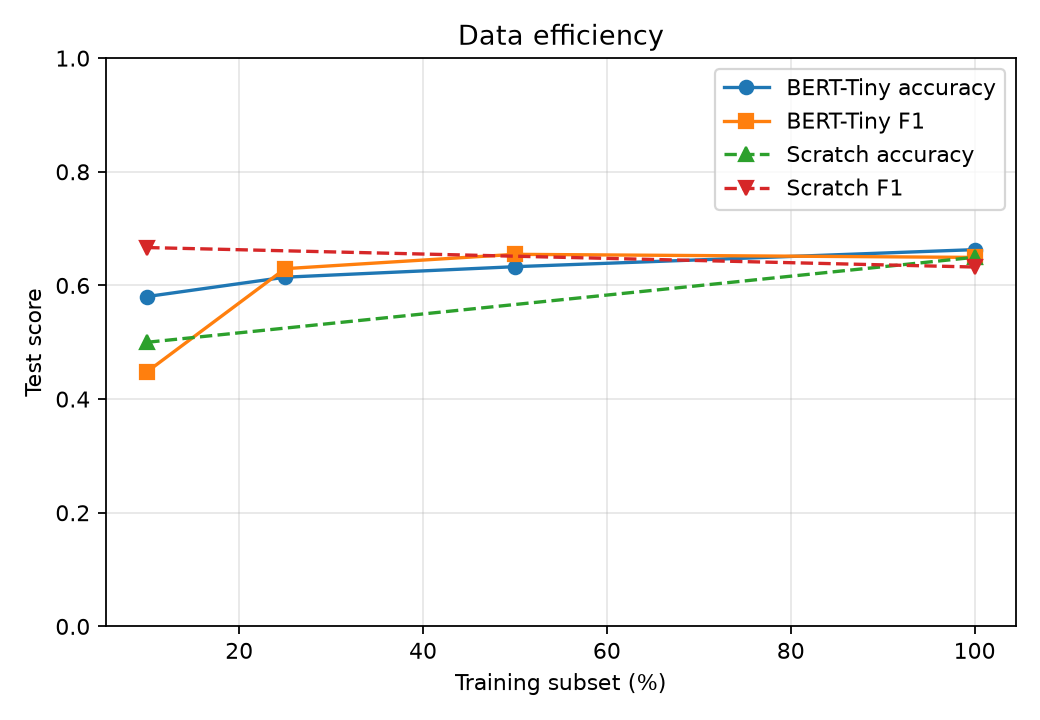

In [6]:
from IPython.display import Image, display
display(Image(filename="data_efficiency.png"))

Đánh giá data efficiency bằng toàn đường cong: xem mức thay đổi accuracy/F1 khi tăng số review train, không chỉ so hai đầu mút.

## 17. Experiment 4 — Maximum Sequence Length
So sánh max length 64, 128, 256 với train/validation/test giữ nguyên. Self-attention có chi phí theo O(T²). Bộ nhớ bên dưới là ước lượng attention-score tensor cho một layer (batch 32, 2 heads, FP32), không phải tổng RAM tiến trình.

In [7]:
seq = results.query("experiment == 'sequence_length'").copy()
seq["estimated_attention_score_MiB_per_layer"] = (
    32 * 2 * seq["max_length"]**2 * 4 / (1024**2)
)
seq[["max_length","accuracy","f1","training_seconds",
     "estimated_attention_score_MiB_per_layer"]].round(4)

,max_length,accuracy,f1,training_seconds,estimated_attention_score_MiB_per_layer
8,64,0.6190,0.5785,26.6440,1.0
9,128,0.6575,0.6295,55.3786,4.0
10,256,0.6845,0.6642,130.2048,16.0


Khi length tăng, model nhận thêm ngữ cảnh nhưng attention memory tăng bình phương. Chỉ nên tăng nếu nội dung giữ lại đem lại cải thiện đủ lớn so với chi phí.

## 18. Experiment 5 — Domain Shift
Train chỉ trên IMDb; kiểm tra trên IMDb test (in-domain) và 1.000 câu đánh giá sản phẩm Amazon của UCI (out-of-domain). Amazon không tham gia train/validation.

In [8]:
domain = results.query("experiment == 'domain_shift'")
in_domain = results.query(
    "experiment == 'pretrained_vs_scratch' and condition == 'BERT-Tiny fine-tuned'"
)
pd.concat([in_domain.assign(domain="IMDb in-domain"),
           domain.assign(domain="Amazon product reviews out-of-domain")],
          ignore_index=True)[["domain","training_examples","accuracy","precision",
                              "recall","f1","training_seconds"]].round(4)

,domain,training_examples,accuracy,precision,recall,f1,training_seconds
0,IMDb in-domain,6000,0.661,0.6569,0.674,0.6654,61.0963
1,Amazon product reviews out-of-domain,6000,0.666,0.7173,0.548,0.6213,53.2575


Pretrained không đồng nghĩa model đã thích nghi với mọi domain. Khác biệt về nội dung, từ vựng và độ dài có thể làm hiệu năng thay đổi; chỉ kết luận trên hai tập đã dùng.

## 19. Application — Sentiment Classification
Bài toán phân loại review thành negative/positive. Báo cáo accuracy, precision, recall, F1 và confusion matrix.

In [9]:
from sklearn.metrics import precision_recall_fscore_support
main = results.query(
    "experiment == 'pretrained_vs_scratch' and condition == 'BERT-Tiny fine-tuned'"
).iloc[0]
main[["accuracy","precision","recall","f1"]].to_frame("BERT-Tiny IMDb test")

,BERT-Tiny IMDb test
accuracy,0.661
precision,0.65692
recall,0.674
f1,0.66535


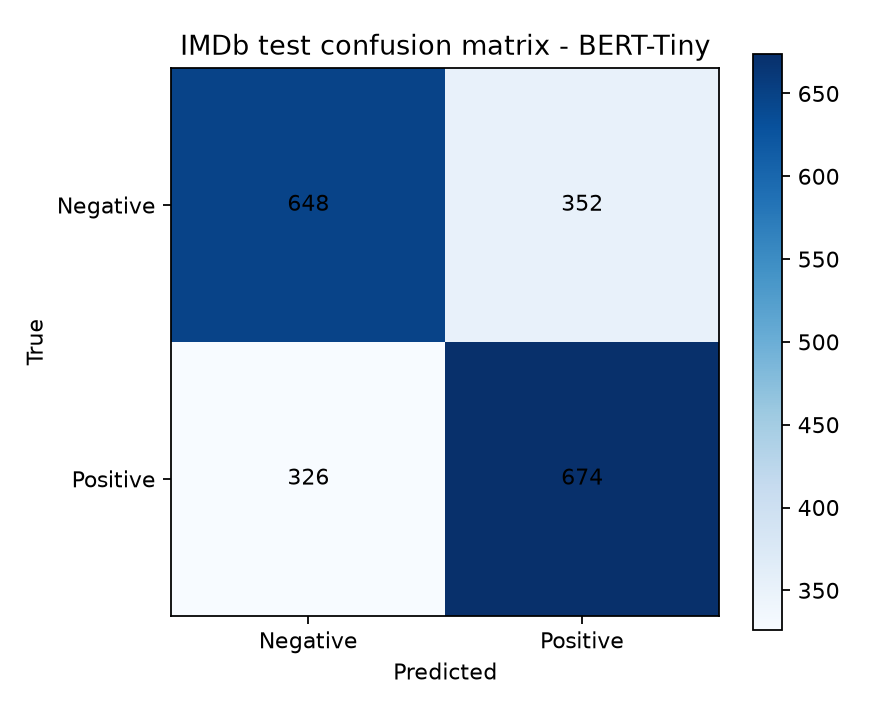

In [10]:
display(Image(filename="confusion_matrix.png"))

Accuracy không cho biết loại lỗi nào phổ biến; confusion matrix cho thấy false positives và false negatives riêng biệt.

## 20. Error Analysis
Chọn tối thiểu 3 false positives, 3 false negatives và 2 dự đoán sai confidence cao. CSV lưu văn bản, nhãn đúng/sai và xác suất.

In [11]:
errors = pd.read_csv("result/error_examples.csv")
errors.assign(text=errors.text.str.slice(0, 260))[
    ["error_type","text","true_label","predicted_label",
     "positive_probability","confidence","confidence_bin"]
]

,error_type,text,true_label,predicted_label,positive_probability,confidence,confidence_bin
0,False Positive,This really is a film of two halves. The first...,0,1,0.768838,0.768838,High
1,False Positive,"Beautiful images, propaganda and history as to...",0,1,0.754942,0.754942,High
2,False Positive,"Jess Franco makes exploitation films, and he h...",0,1,0.749002,0.749002,Medium
3,False Negative,"Good, boring or bad? It's good. Worth your mon...",1,0,0.292826,0.707174,Medium
4,False Negative,The mystery and its solution was a great noir ...,1,0,0.293321,0.706679,Medium
5,False Negative,"No real plot, no character development, no Sco...",1,0,0.295845,0.704155,Medium
6,High-confidence wrong,This really is a film of two halves. The first...,0,1,0.768838,0.768838,High
7,High-confidence wrong,"Beautiful images, propaganda and history as to...",0,1,0.754942,0.754942,High


Phân loại từng ví dụ theo negation, sarcasm, long-range dependency, ambiguous sentiment, domain-specific expression, rare word, tokenization/context, truncation hoặc label ambiguity. Hypothesis phải dựa vào câu thực tế.

## 21. Confidence Analysis
Confidence là xác suất lớn nhất của hai lớp. Chia thành Low ≤0.60, Medium >0.60–0.75, High >0.75 rồi so sánh confidence trung bình với accuracy thực tế.

In [12]:
pd.read_csv("result/confidence_analysis.csv").round(4)

,confidence_bin,count,mean_confidence,accuracy
0,Low,897,0.5505,0.5674
1,Medium,1073,0.6617,0.7316
2,High,30,0.7618,0.9333


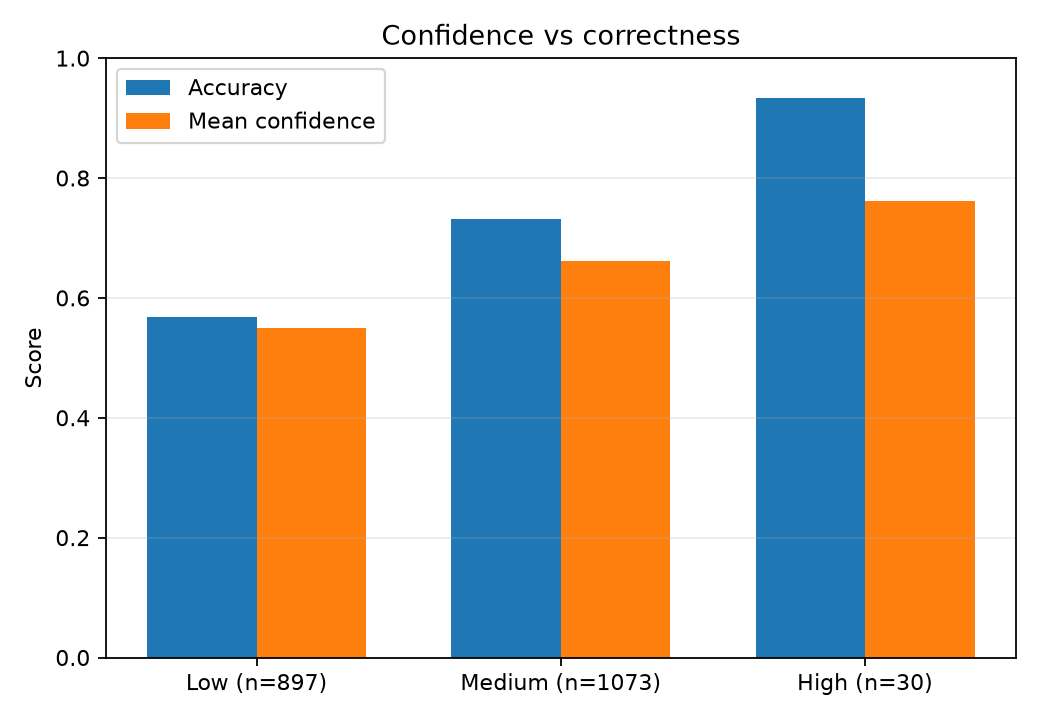

In [13]:
display(Image(filename="confidence_analysis.png"))

Confidence cao không bảo đảm prediction đúng. Đồ thị so sánh xác suất model tự tin với tỷ lệ dự đoán đúng trong từng nhóm.

## 22. Ablation / Analysis
Ablation được chọn: giảm lượng train từ 100% xuống 10%. Validation/test giữ nguyên; so sánh BERT-Tiny với scratch trên các hàng có trong results.csv. Đây là kiểm tra có kiểm soát trên một seed.

In [14]:
ablation = results.query(
    "experiment in ['data_efficiency','data_efficiency_scratch'] and "
    "condition in ['10%','100%','Scratch 10%','Scratch 100%']"
)
ablation[["experiment","condition","training_examples","accuracy","f1"]].round(4)

,experiment,condition,training_examples,accuracy,f1
4,data_efficiency,10%,600,0.5805,0.4484
7,data_efficiency,100%,6000,0.6630,0.6493
12,data_efficiency_scratch,Scratch 10%,600,0.5000,0.6667
13,data_efficiency_scratch,Scratch 100%,6000,0.6495,0.6324


## 23. Reproducibility
Ghi lại model/tokenizer, dataset và split, sequence length, batch size, learning rate, epoch, optimizer, seed, hardware và kết quả. Thời gian trong bảng là thời gian train; không tính tải checkpoint/tokenization/evaluation.

In [15]:
import json
with open("result/reproducibility.json", encoding="utf-8") as f:
    repro = json.load(f)
pd.Series({k:v for k,v in repro.items() if k != "audit"}, name="value").to_frame()

,value
seed,2026
model,prajjwal1/bert-tiny
tokenizer,prajjwal1/bert-tiny
dataset,Audited IMDb 10k subset; UCI Amazon product-re...
train_split,6000
validation_split,2000
test_split,2000
max_sequence_lengths,"[64, 128, 256]"
batch_size,32
optimizer,AdamW
